In [2]:
!pip install yfinance pandas numpy matplotlib seaborn plotly scipy --quiet

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
from datetime import datetime

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import yfinance as yf

In [4]:
# Display Options

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", "{:.4f}".format)

# Plot Style

plt.style.use("ggplot")
sns.set_theme(style="darkgrid")

# Figure Size

plt.rcParams["figure.figsize"] = (14,7)

print("Notebook Configuration Complete")

Notebook Configuration Complete


In [5]:
# Benchmark

BENCHMARK = "SPY"

# Risk Free Rate

RISK_FREE = "^IRX"

# Time Period

START_DATE = "2010-01-01"
END_DATE = datetime.today().strftime("%Y-%m-%d")

print("Start Date :", START_DATE)
print("End Date   :", END_DATE)

Start Date : 2010-01-01
End Date   : 2026-08-04


In [6]:
# ======================================================
# Stock Universe
# ======================================================

stocks = [

"AAPL","MSFT","NVDA","AMZN","GOOGL",

"META","TSLA","JPM","XOM","UNH",

"V","MA","JNJ","PG","HD",

"BAC","ABBV","KO","PEP","MRK",

"CVX","ADBE","CSCO","CRM","NFLX",

"AMD","MCD","WMT","INTC","QCOM",

"ACN","TXN","ABT","LIN","NKE",

"DHR","ORCL","UPS","PM","IBM",

"HON","AMGN","LOW","CAT","RTX",

"GS","BLK","MS","GE","T"
]

print("Number of Stocks :", len(stocks))

Number of Stocks : 50


In [7]:
# ======================================================
# Download Stock Data
# ======================================================

stock_data = yf.download(
    tickers=stocks,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=True
)

[*********************100%***********************]  50 of 50 completed


In [8]:
# ======================================================
# Check Dataset Information
# ======================================================

print("Dataset Shape:", stock_data.shape)
print("\nColumns:\n")
print(stock_data.columns)

print("\nFirst 5 Rows:\n")
display(stock_data.head())

Dataset Shape: (4170, 250)

Columns:

MultiIndex([( 'Close', 'AAPL'),
            ( 'Close', 'ABBV'),
            ( 'Close',  'ABT'),
            ( 'Close',  'ACN'),
            ( 'Close', 'ADBE'),
            ( 'Close',  'AMD'),
            ( 'Close', 'AMGN'),
            ( 'Close', 'AMZN'),
            ( 'Close',  'BAC'),
            ( 'Close',  'BLK'),
            ...
            ('Volume', 'QCOM'),
            ('Volume',  'RTX'),
            ('Volume',    'T'),
            ('Volume', 'TSLA'),
            ('Volume',  'TXN'),
            ('Volume',  'UNH'),
            ('Volume',  'UPS'),
            ('Volume',    'V'),
            ('Volume',  'WMT'),
            ('Volume',  'XOM')],
           names=['Price', 'Ticker'], length=250)

First 5 Rows:



Price       Close                                                             \
Ticker       AAPL ABBV     ABT     ACN    ADBE    AMD    AMGN   AMZN     BAC   
Date                                                                           
2010-01-04 6.4065  NaN 18.0788 30.8563 37.0900 9.7000 38.7485 6.6950 12.0382   
2010-01-05 6.4176  NaN 17.9327 31.0470 37.7000 9.7100 38.4129 6.7345 12.4295   
2010-01-06 6.3155  NaN 18.0323 31.3771 37.6200 9.5700 38.1242 6.6125 12.5753   
2010-01-07 6.3038  NaN 18.1817 31.3478 36.8900 9.4700 37.7751 6.5000 12.9896   
2010-01-08 6.3457  NaN 18.2747 31.2231 36.6900 9.4300 38.1108 6.6760 12.8745   

Price                                                                        \
Ticker          BLK     CAT     CRM    CSCO     CVX     DHR      GE   GOOGL   
Date                                                                          
2010-01-04 156.5750 39.0519 18.3869 15.8304 40.8909 15.0955 53.4581 15.5466   
2010-01-05 157.2510 39.5188 18.3083 15.7598 41.1806 15.0775 53.7349 15.4781   
2010-01-06 154.0089 39.6389 18.2763 15.6573 41.1857 15.1056 53.4581 15.0879   
2010-01-07 155.7022 39.7990 18.1952 15.7278 41.0306 15.2301 56.2262 14.7367   
2010-01-08 156.7982 40.2458 18.2222 15.8111 41.1030 15.4430 57.4372 14.9332   

Price                                                                        \
Ticker           GS      HD     HON     IBM    INTC     JNJ     JPM      KO   
Date                                                                          
2010-01-04 129.3874 19.2971 26.5467 71.9388 13.5194 39.9748 28.1524 17.2052   
2010-01-05 131.6750 19.4384 26.5993 71.0698 13.5130 39.5113 28.6977 16.9971   
2010-01-06 130.2695 19.3711 26.5993 70.6081 13.4676 39.8327 28.8554 16.9911   
2010-01-07 132.8186 19.6000 27.1125 70.3637 13.3381 39.5484 29.4270 16.9489   
2010-01-08 130.3068 19.5057 27.7112 71.0698 13.4871 39.6843 29.3547 16.6352   

Price                                                                    \
Ticker         LIN     LOW      MA     MCD META     MRK      MS    MSFT   
Date                                                                      
2010-01-04 59.8218 17.0260 23.5027 40.0607  NaN 20.3147 21.5085 23.0275   
2010-01-05 58.7070 16.8496 23.4332 39.7544  NaN 20.3970 22.2948 23.0349   
2010-01-06 59.2278 16.8937 23.3993 39.2120  NaN 20.6715 22.5801 22.8936   
2010-01-07 59.3818 17.3789 23.2464 39.4992  NaN 20.7044 22.9071 22.6555   
2010-01-08 59.7705 17.3421 23.2546 39.4609  NaN 20.6934 22.4409 22.8117   

Price                                                                     \
Ticker       NFLX     NKE   NVDA    ORCL     PEP      PG      PM    QCOM   
Date                                                                       
2010-01-04 0.7640 13.0620 0.4233 19.8782 37.2347 37.5805 22.9447 31.0515   
2010-01-05 0.7359 13.1140 0.4295 19.8542 37.6846 37.5928 22.7448 31.7990   
2010-01-06 0.7617 13.0340 0.4322 19.5662 37.3077 37.4145 22.7448 31.4881   
2010-01-07 0.7486 13.1619 0.4237 19.5022 37.0705 37.2116 23.0284 32.4010   
2010-01-08 0.7614 13.1360 0.4247 19.7422 36.9489 37.1624 22.9028 32.7251   

Price                                                                   \
Ticker         RTX      T TSLA     TXN     UNH     UPS       V     WMT   
Date                                                                     
2010-01-04 30.6750 6.5856  NaN 16.8524 24.2691 32.9526 19.5647 12.9092   
2010-01-05 30.2168 6.5533  NaN 16.7553 24.2306 33.0092 19.3405 12.7806   
2010-01-06 30.0583 6.4890  NaN 16.6321 24.4692 32.7657 19.0808 12.7521   
2010-01-07 30.1868 6.4161  NaN 16.6840 25.4083 32.5164 19.2583 12.7592   
2010-01-08 30.2467 6.3691  NaN 17.0663 25.1696 34.0797 19.3116 12.6949   

Price                High                                                     \
Ticker         XOM   AAPL ABBV     ABT     ACN    ADBE    AMD    AMGN   AMZN   
Date                                                                           
2010-01-04 37.3773 6.4211  NaN 18.1120 30.9517 37.

In [9]:
# ======================================================
# Missing Value Analysis
# ======================================================

missing = stock_data.isnull().sum()

print("Total Missing Values:")
print(missing[missing > 0])

print("\nTotal Missing Cells:", stock_data.isnull().sum().sum())

Total Missing Values:
Price   Ticker
Close   ABBV      754
        META      599
        TSLA      122
High    ABBV      754
        META      599
        TSLA      122
Low     ABBV      754
        META      599
        TSLA      122
Open    ABBV      754
        META      599
        TSLA      122
Volume  ABBV      754
        META      599
        TSLA      122
dtype: int64

Total Missing Cells: 7375


In [10]:
# ======================================================
# Extract Adjusted Closing Prices
# ======================================================

close_prices = stock_data["Close"]

display(close_prices.head())

Ticker,AAPL,ABBV,ABT,ACN,ADBE,AMD,AMGN,AMZN,BAC,BLK,CAT,CRM,CSCO,CVX,DHR,GE,GOOGL,GS,HD,HON,IBM,INTC,JNJ,JPM,KO,LIN,LOW,MA,MCD,META,MRK,MS,MSFT,NFLX,NKE,NVDA,ORCL,PEP,PG,PM,QCOM,RTX,T,TSLA,TXN,UNH,UPS,V,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2010-01-04,6.4065,NaN,18.0788,30.8563,37.0900,9.7000,38.7485,6.6950,12.0382,156.5750,39.0519,18.3869,15.8304,40.8909,15.0955,53.4581,15.5466,129.3874,19.2971,26.5467,71.9388,13.5194,39.9748,28.1524,17.2052,59.8218,17.0260,23.5027,40.0607,NaN,20.3147,21.5085,23.0275,0.7640,13.0620,0.4233,19.8782,37.2347,37.5805,22.9447,31.0515,30.6750,6.5856,NaN,16.8524,24.2691,32.9526,19.5647,12.9092,37.3773
2010-01-05,6.4176,NaN,17.9327,31.0470,37.7000,9.7100,38.4129,6.7345,12.4295,157.2510,39.5188,18.3083,15.7598,41.1806,15.0775,53.7349,15.4781,131.6750,19.4384,26.5993,71.0698,13.5130,39.5113,28.6977,16.9971,58.7070,16.8496,23.4332,39.7544,NaN,20.3970,22.2948,23.0349,0.7359,13.1140,0.4295,19.8542,37.6846,37.5928,22.7448,31.7990,30.2168,6.5533,NaN,16.7553,24.2306,33.0092,19.3405,12.7806,37.5232
2010-01-06,6.3155,NaN,18.0323,31.3771,37.6200,9.5700,38.1242,6.6125,12.5753,154.0089,39.6389,18.2763,15.6573,41.1857,15.1056,53.4581,15.0879,130.2695,19.3711,26.5993,70.6081,13.4676,39.8327,28.8554,16.9911,59.2278,16.8937,23.3993,39.2120,NaN,20.6715,22.5801,22.8936,0.7617,13.0340,0.4322,19.5662,37.3077,37.4145,22.7448,31.4881,30.0583,6.4890,NaN,16.6321,24.4692,32.7657,19.0808,12.7521,37.8475
2010-01-07,6.3038,NaN,18.1817,31.3478,36.8900,9.4700,37.7751,6.5000,12.9896,155.7022,39.7990,18.1952,15.7278,41.0306,15.2301,56.2262,14.7367,132.8186,19.6000,27.1125,70.3637,13.3381,39.5484,29.4270,16.9489,59.3818,17.3789,23.2464,39.4992,NaN,20.7044,22.9071,22.6555,0.7486,13.1619,0.4237,19.5022,37.0705,37.2116,23.0284,32.4010,30.1868,6.4161,NaN,16.6840,25.4083,32.5164,19.2583,12.7592,37.7286
2010-01-08,6.3457,NaN,18.2747,31.2231,36.6900,9.4300,38.1108,6.6760,12.8745,156.7982,40.2458,18.2222,15.8111,41.1030,15.4430,57.4372,14.9332,130.3068,19.5057,27.7112,71.0698,13.4871,39.6843,29.3547,16.6352,59.7705,17.3421,23.2546,39.4609,NaN,20.6934,22.4409,22.8117,0.7614,13.1360,0.4247,19.7422,36.9489,37.1624,22.9028,32.7251,30.2467,6.3691,NaN,17.0663,25.1696,34.0797,19.3116,12.6949,37.5773


In [11]:
# ======================================================
# Basic Information
# ======================================================

print("Number of Stocks:", len(close_prices.columns))
print("Number of Trading Days:", len(close_prices))

print("\nStock Names:\n")
print(close_prices.columns.tolist())


Number of Stocks: 50
Number of Trading Days: 4170

Stock Names:

['AAPL', 'ABBV', 'ABT', 'ACN', 'ADBE', 'AMD', 'AMGN', 'AMZN', 'BAC', 'BLK', 'CAT', 'CRM', 'CSCO', 'CVX', 'DHR', 'GE', 'GOOGL', 'GS', 'HD', 'HON', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'LIN', 'LOW', 'MA', 'MCD', 'META', 'MRK', 'MS', 'MSFT', 'NFLX', 'NKE', 'NVDA', 'ORCL', 'PEP', 'PG', 'PM', 'QCOM', 'RTX', 'T', 'TSLA', 'TXN', 'UNH', 'UPS', 'V', 'WMT', 'XOM']


In [12]:
# ======================================================
# Create Project Folders
# ======================================================

folders = [
    "data",
    "data/raw",
    "data/processed",
    "outputs",
    "outputs/plots"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Folders Created Successfully!")

Folders Created Successfully!


In [13]:
# ======================================================
# Save Raw Data
# ======================================================

close_prices.to_csv("data/raw/raw_stock_prices.csv")

print("Raw stock prices saved successfully!")

Raw stock prices saved successfully!


In [14]:
# ======================================================
# Download Benchmark Data
# ======================================================

benchmark = yf.download(
    "SPY",
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

benchmark.to_csv("data/raw/benchmark.csv")

display(benchmark.head())

Price,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY
Date,,,,,
2010-01-04,84.5785,84.6233,83.2202,83.8620,118944600
2010-01-05,84.8023,84.8396,84.2202,84.5262,111579900
2010-01-06,84.8621,85.0710,84.6531,84.7203,116074400
2010-01-07,85.2203,85.3248,84.4666,84.7054,131091100
2010-01-08,85.5039,85.5412,84.8247,84.9964,126402800


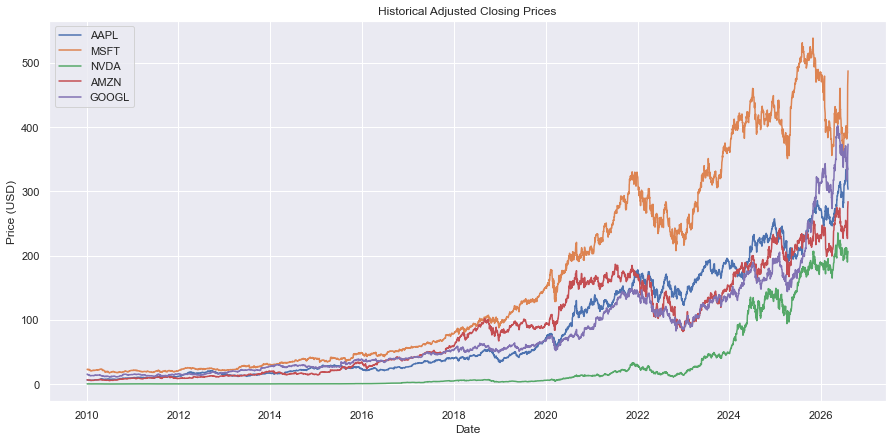

In [15]:
# ======================================================
# Plot Sample Stock Prices
# ======================================================

sample_stocks = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL"]

plt.figure(figsize=(15,7))

for stock in sample_stocks:
    plt.plot(close_prices.index, close_prices[stock], label=stock)

plt.title("Historical Adjusted Closing Prices")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)

plt.show()

In [16]:
# ======================================================
# Phase 1 Summary
# ======================================================

print("="*50)
print("PHASE 1 COMPLETED")
print("="*50)

print(f"Stocks Downloaded : {len(close_prices.columns)}")
print(f"Trading Days      : {len(close_prices)}")
print(f"Start Date        : {close_prices.index.min().date()}")
print(f"End Date          : {close_prices.index.max().date()}")

print("\nFiles Created:")
print("✔ data/raw/raw_stock_prices.csv")
print("✔ data/raw/benchmark.csv")

print("\nReady for Phase 2: Data Cleaning")

PHASE 1 COMPLETED
Stocks Downloaded : 50
Trading Days      : 4170
Start Date        : 2010-01-04
End Date          : 2026-08-03

Files Created:
✔ data/raw/raw_stock_prices.csv
✔ data/raw/benchmark.csv

Ready for Phase 2: Data Cleaning


In [17]:
# ======================================================
# Save Complete OHLCV Dataset
# ======================================================

stock_data.to_csv("data/raw/full_stock_data.csv")

print("Complete OHLCV dataset saved successfully!")

Complete OHLCV dataset saved successfully!
